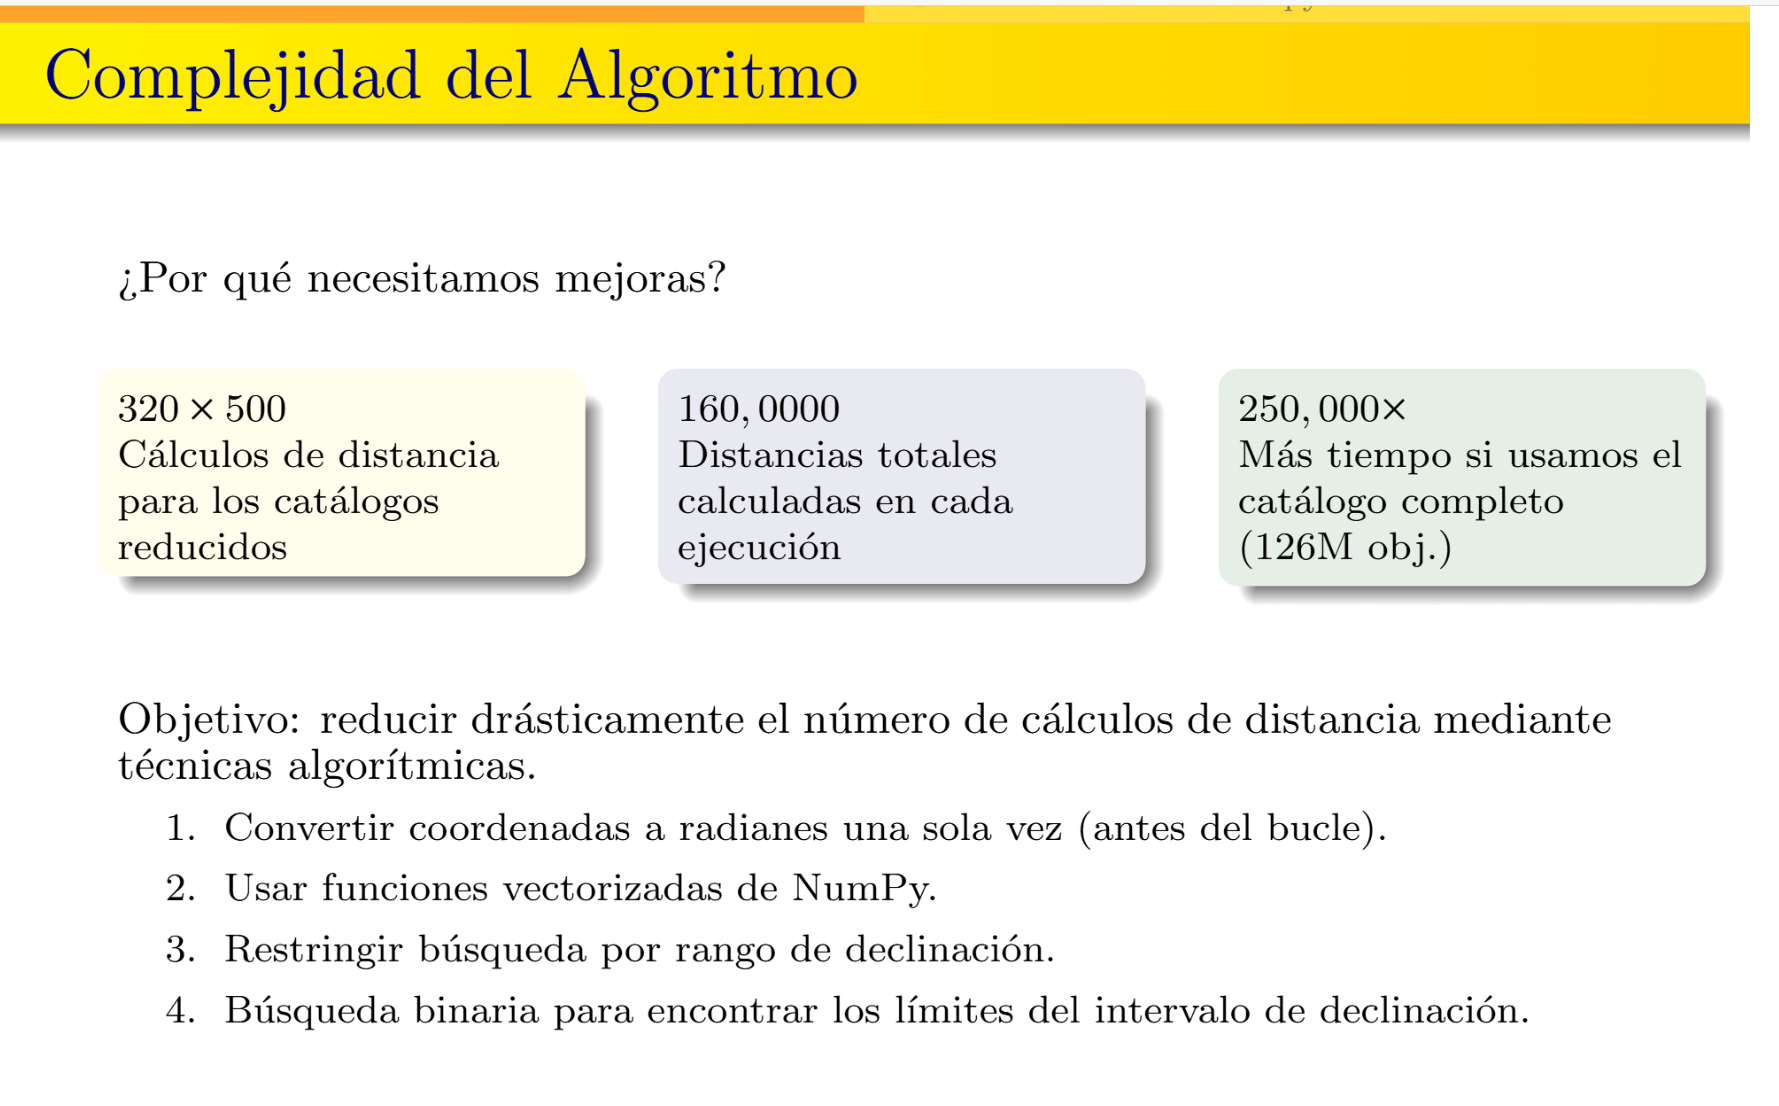

In [1]:
import time
import numpy as np

# Carga del catalogo BSS 
bbs_raw = np.loadtxt("J_MNRAS_384_775/table2.dat", usecols=range(1, 7))
n_bss = bbs_raw.shape[0]
bss_cat = np.zeros((n_bss, 3))

for i in range(n_bss):
    id_bss = float(i + 1)
    h1 = bbs_raw[i, 0]
    m1 = bbs_raw[i, 1]
    s1 = bbs_raw[i, 2]
    ra1_deg = 15.0 * (h1 + (m1 / 60.0) + (s1 / 3600.0))

    d1 = bbs_raw[i, 3]
    dm1 = bbs_raw[i, 4]
    ds1 = bbs_raw[i, 5]
    if d1 >= 0:
        dec1_deg = d1 + (dm1 / 60.0) + (ds1 / 3600.0)
    else:
        dec1_deg = -1.0 * (-d1 + (dm1 / 60.0) + (ds1 / 3600.0))

    bss_cat[i, 0] = id_bss
    bss_cat[i, 1] = ra1_deg
    bss_cat[i, 2] = dec1_deg

# Carga del catalogo SuperCOSMOS 
super_raw = np.loadtxt("super.csv", delimiter=",", skiprows=1, usecols=[0, 1])
n_super = super_raw.shape[0]
super_cat = np.zeros((n_super, 3))

for j in range(n_super):
    id_super = float(j + 1)
    ra2_deg = super_raw[j, 0]
    dec2_deg = super_raw[j, 1]
    super_cat[j, 0] = id_super
    super_cat[j, 1] = ra2_deg
    super_cat[j, 2] = dec2_deg

print("BSS:", bss_cat.shape, "| SuperCOSMOS:", super_cat.shape)

BSS: (320, 3) | SuperCOSMOS: (500, 3)


In [2]:
# MEJORA 1 (Conversion a radianes antes de los bucles) y MEJORA 3 y 4 (Ordenar catalogo 2 por declinacion y usar np.searchsorted)
bss_ra_rad = np.radians(bss_cat[:, 1])
bss_dec_rad = np.radians(bss_cat[:, 2])
bss_ids = bss_cat[:, 0].astype(int)

super_ra_rad = np.radians(super_cat[:, 1])
super_dec_rad = np.radians(super_cat[:, 2])
super_ids = super_cat[:, 0].astype(int)

# Construir arreglo en radianes de SuperCOSMOS con columnas [id_super, ra_rad, dec_rad]
super_rad_cat = np.column_stack((super_ids, super_ra_rad, super_dec_rad))

# Ordenar catalogo 2 por declinacion en radianes (columna indice 2)
orden_dec = np.argsort(super_rad_cat[:, 2])
super_sorted = super_rad_cat[orden_dec]
dec_sorted = super_sorted[:, 2]

print("Catalogo 2 ordenado por declinacion. Primeras 3 filas (ID, RA_rad, Dec_rad):")
print(super_sorted[:3])

Catalogo 2 ordenado por declinacion. Primeras 3 filas (ID, RA_rad, Dec_rad):
[[ 1.93000000e+02  2.39794640e+00 -1.53451200e+00]
 [ 1.00000000e+00  1.05274072e-03 -1.49498154e+00]
 [ 2.68000000e+02  3.11063995e+00 -1.46155810e+00]]


In [3]:
#  MEJORA 2 (operaciones vectorizadas con NumPy y np.argmin)
max_dist_10_arcsec = 10.0
max_dist_10_deg = max_dist_10_arcsec / 3600.0
r_10_rad = np.radians(max_dist_10_deg)

t_inicio_10 = time.perf_counter()

matches_10 = []
non_matches_10 = []

for i in range(len(bss_ids)):
    id1 = int(bss_ids[i])
    ra1 = bss_ra_rad[i]
    dec1 = bss_dec_rad[i]

    # Limites inferior y superior de declinacion en radianes
    dec_min_busqueda = dec1 - r_10_rad
    dec_max_busqueda = dec1 + r_10_rad

    # Busqueda binaria de indices de inicio y fin en dec_sorted
    idx_inicio = np.searchsorted(dec_sorted, dec_min_busqueda, side="left")
    idx_fin = np.searchsorted(dec_sorted, dec_max_busqueda, side="right")

    # Subconjunto candidato dentro del rango de declinacion
    sub_cat2 = super_sorted[idx_inicio:idx_fin]

    if len(sub_cat2) == 0:
        non_matches_10.append(id1)
        continue

    sub_ids2 = sub_cat2[:, 0].astype(int)
    sub_ra2 = sub_cat2[:, 1]
    sub_dec2 = sub_cat2[:, 2]

    # Formula de Haversine vectorizada sobre todo el subconjunto
    dif_dec = np.abs(dec1 - sub_dec2) / 2.0
    dif_ra = np.abs(ra1 - sub_ra2) / 2.0
    seno_cuad_dec = np.sin(dif_dec) ** 2
    cos_dec1 = np.cos(dec1)
    cos_sub_dec2 = np.cos(sub_dec2)
    seno_cuad_ra = np.sin(dif_ra) ** 2
    termino_a = seno_cuad_dec
    termino_b = cos_dec1 * cos_sub_dec2 * seno_cuad_ra
    suma_ab = termino_a + termino_b
    raiz_ab = np.sqrt(suma_ab)
    distancias_rad = 2.0 * np.arcsin(raiz_ab)

    # Indice del minimo sin bucle interno
    idx_min = np.argmin(distancias_rad)
    min_dist_rad = distancias_rad[idx_min]
    best_id2 = int(sub_ids2[idx_min])

    if min_dist_rad <= r_10_rad:
        min_dist_deg = np.degrees(min_dist_rad)
        min_dist_arcsec = min_dist_deg * 3600.0
        matches_10.append((id1, best_id2, float(min_dist_arcsec)))
    else:
        non_matches_10.append(id1)

# Ordenar ambas listas por el ID del primer catalogo
matches_10.sort(key=lambda item: item[0])
non_matches_10.sort()

t_fin_10 = time.perf_counter()
tiempo_10 = t_fin_10 - t_inicio_10

print("Tiempo (10 arcsec) [s]:", tiempo_10)
print("Total matches (10 arcsec):", len(matches_10))
print("Total non-matches (10 arcsec):", len(non_matches_10))
print("Primeros 5 matches:", matches_10[:5])
print("Primeros 10 non-matches:", non_matches_10[:10])

Tiempo (10 arcsec) [s]: 0.016519733995664865
Total matches (10 arcsec): 131
Total non-matches (10 arcsec): 189
Primeros 5 matches: [(1, 2, 0.39558999379356213), (2, 4, 2.753944548207298), (3, 5, 0.7510807033454759), (4, 6, 0.4632227988150214), (7, 11, 0.27598446324039627)]
Primeros 10 non-matches: [5, 6, 11, 14, 29, 45, 47, 52, 57, 58]


In [4]:

max_dist_5_arcsec = 5.0
max_dist_5_deg = max_dist_5_arcsec / 3600.0
r_5_rad = np.radians(max_dist_5_deg)

t_inicio_5 = time.perf_counter()

matches_5 = []
non_matches_5 = []

for i in range(len(bss_ids)):
    id1 = int(bss_ids[i])
    ra1 = bss_ra_rad[i]
    dec1 = bss_dec_rad[i]

    dec_min_busqueda = dec1 - r_5_rad
    dec_max_busqueda = dec1 + r_5_rad

    idx_inicio = np.searchsorted(dec_sorted, dec_min_busqueda, side="left")
    idx_fin = np.searchsorted(dec_sorted, dec_max_busqueda, side="right")

    sub_cat2 = super_sorted[idx_inicio:idx_fin]

    if len(sub_cat2) == 0:
        non_matches_5.append(id1)
        continue

    sub_ids2 = sub_cat2[:, 0].astype(int)
    sub_ra2 = sub_cat2[:, 1]
    sub_dec2 = sub_cat2[:, 2]

    dif_dec = np.abs(dec1 - sub_dec2) / 2.0
    dif_ra = np.abs(ra1 - sub_ra2) / 2.0
    seno_cuad_dec = np.sin(dif_dec) ** 2
    cos_dec1 = np.cos(dec1)
    cos_sub_dec2 = np.cos(sub_dec2)
    seno_cuad_ra = np.sin(dif_ra) ** 2
    termino_a = seno_cuad_dec
    termino_b = cos_dec1 * cos_sub_dec2 * seno_cuad_ra
    suma_ab = termino_a + termino_b
    raiz_ab = np.sqrt(suma_ab)
    distancias_rad = 2.0 * np.arcsin(raiz_ab)

    idx_min = np.argmin(distancias_rad)
    min_dist_rad = distancias_rad[idx_min]
    best_id2 = int(sub_ids2[idx_min])

    if min_dist_rad <= r_5_rad:
        min_dist_deg = np.degrees(min_dist_rad)
        min_dist_arcsec = min_dist_deg * 3600.0
        matches_5.append((id1, best_id2, float(min_dist_arcsec)))
    else:
        non_matches_5.append(id1)

matches_5.sort(key=lambda item: item[0])
non_matches_5.sort()

t_fin_5 = time.perf_counter()
tiempo_5 = t_fin_5 - t_inicio_5

print("Tiempo (5 arcsec) [s]:", tiempo_5)
print("Total matches (5 arcsec):", len(matches_5))
print("Total non-matches (5 arcsec):", len(non_matches_5))
print("Primeros 5 matches:", matches_5[:5])
print("Primeros 10 non-matches:", non_matches_5[:10])

Tiempo (5 arcsec) [s]: 0.010721904982347041
Total matches (5 arcsec): 123
Total non-matches (5 arcsec): 197
Primeros 5 matches: [(1, 2, 0.39558999379356213), (2, 4, 2.753944548207298), (3, 5, 0.7510807033454759), (4, 6, 0.4632227988150214), (7, 11, 0.27598446324039627)]
Primeros 10 non-matches: [5, 6, 11, 14, 29, 45, 47, 52, 57, 58]
